## <center> Implementation from Scratch

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Simple Linear Regression ($y = wx + b$)

### 1. The Goal
Simple Linear Regression is a supervised learning algorithm used to predict a **continuous** output ($y$) based on a **single** input feature ($x$). It assumes a linear relationship between the two.

The mathematical model is:
$$y = wx + b$$

---

### 2. The Cost Function
To find the "best" line, we minimize the **Mean Squared Error (MSE)**, which measures the average squared distance between actual points ($y$) and predicted points ($\hat{y}$):



$$J(w, b) = \frac{1}{n} \sum_{i=1}^{n} (y_i - (wx_i + b))^2$$

---

### 3. Optimization: Gradient Descent
We use **Gradient Descent** to update $w$ and $b$ by taking steps in the opposite direction of the gradient (the slope of the error).

#### Partial Derivatives (Gradients)
To compute how much the cost function $J(w, b)$ changes with respect to $w$ and $b$, we take the partial derivatives:

* **Gradient with respect to Weight ($w$):**
  $$\frac{\partial J}{\partial w} = -\frac{2}{n} \sum_{i=1}^{n} x_i (y_i - (wx_i + b))$$
  *(In code: `dw = (-2/n) * np.sum((y - y_pred) * X)`)*

* **Gradient with respect to Bias ($b$):**
  $$\frac{\partial J}{\partial b} = -\frac{2}{n} \sum_{i=1}^{n} (y_i - (wx_i + b))$$
  *(In code: `db = (-2/n) * np.sum(y - y_pred)`)*

---

#### Parameter Update Rules
Using learning rate $\alpha$, we update the parameters in each iteration:

1. **Update Weight:** 
   $$w := w - \alpha * dw$$
   *(In code: `self.w -= self.learning_rate * dw`)*

2. **Update Bias:** 
   $$b := b - \alpha * db$$
   *(In code: `self.b -= self.learning_rate * db`)*



---

### 4. Assumptions
*   **Linearity:** The relationship between $X$ and $Y$ is linear.
*   **Independence:** Data points are independent of each other.
*   **Normality:** The residuals (errors) follow a normal distribution.

---

In [3]:
class MySimpleLinearRegression:
    def __init__(self, learning_rate = 0.05, epochs = 1000):
        """
        Initialize the model parameters
        """
        self.epochs = epochs
        self.learning_rate = learning_rate
        self.w = 0.0
        self.b = 0.0
        self.cost_history = [] # To track cost

    def fit(self, X, y):
        """ 
        Train the model using Gradient Descent
        """
        n = float(len(X))

        for i in range(self.epochs):
            # 1. Forward Pass (Prediction)
            y_pred = self.w * X + self.b

            # 2. Calculate Cost (MSE)
            cost = (1/n) * np.sum((y - y_pred)**2)
            self.cost_history.append(cost)

            # 3. Calculate Gradients (Derivatives)
            dw = (-2/n) * np.sum((y - y_pred) * X)
            db = (-2/n) * np.sum(y - y_pred)

            # 4. Update Parameters
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            if i % (self.epochs // 10) == 0:
                print(f"Epoch {i}: Cost {cost:.4f}")
    
    def predict(self, X):
        """ 
        Predict the output for given input X
        """

        return self.w * X + self.b


Training the model...
Epoch 0: Cost 30.0448
Epoch 100: Cost 0.0572
Epoch 200: Cost 0.0457
Epoch 300: Cost 0.0399
Epoch 400: Cost 0.0366
Epoch 500: Cost 0.0347
Epoch 600: Cost 0.0337
Epoch 700: Cost 0.0331
Epoch 800: Cost 0.0327
Epoch 900: Cost 0.0325
Learned Weight: 2.8677
Learned Bias: 4.0634


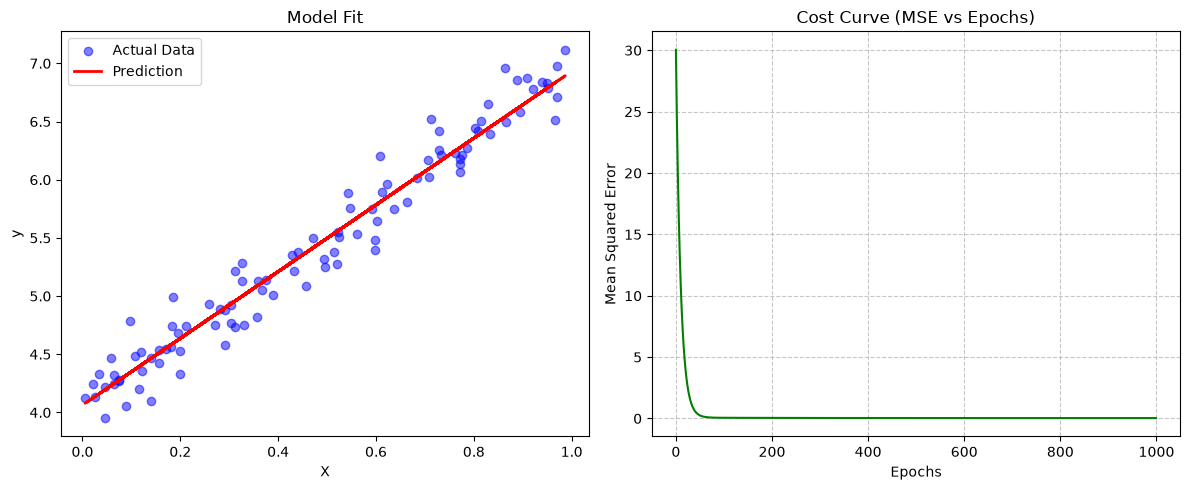

In [6]:
# --- Usage Section ---

# 1. Data Setup  (If you have real data you can use it)
np.random.seed(42)
X = np.random.rand(100, 1)
y = 3 * X + 4 + np.random.randn(100, 1) * 0.2  # y = 3x + 4 and last term corresponds to noise

# 2. Model Initialization & Training
model = MySimpleLinearRegression(learning_rate=0.02, epochs=1000)
print("Training the model...")
model.fit(X, y)

# 3. Output Results
print(f"Learned Weight: {model.w:.4f}")
print(f"Learned Bias: {model.b:.4f}")

# 4. Visualization
# Subplot 1: Data and Regression Line
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X, y, color='blue', alpha=0.5, label='Actual Data')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Prediction')
plt.title("Model Fit")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()

# Subplot 2: Cost Curve (Learning Curve)
plt.subplot(1, 2, 2)
plt.plot(range(len(model.cost_history)), model.cost_history, color='green')
plt.title("Cost Curve (MSE vs Epochs)")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## <center> Implementation using Scikit Learn 

📊 PARAMETER COMPARISON
------------------------------
Attribute       | Manual (GD)  | Scikit-Learn
---------------------------------------------
Weight (w)      | 2.8677       | 2.9080      
Bias (b)        | 4.0634       | 4.0430      

📝 FINAL PERFORMANCE VERDICT
----------------------------------------
Scratch MSE: 0.032408
Sklearn MSE: 0.032263
----------------------------------------
Result: Sklearn is more accurate by 0.00014444


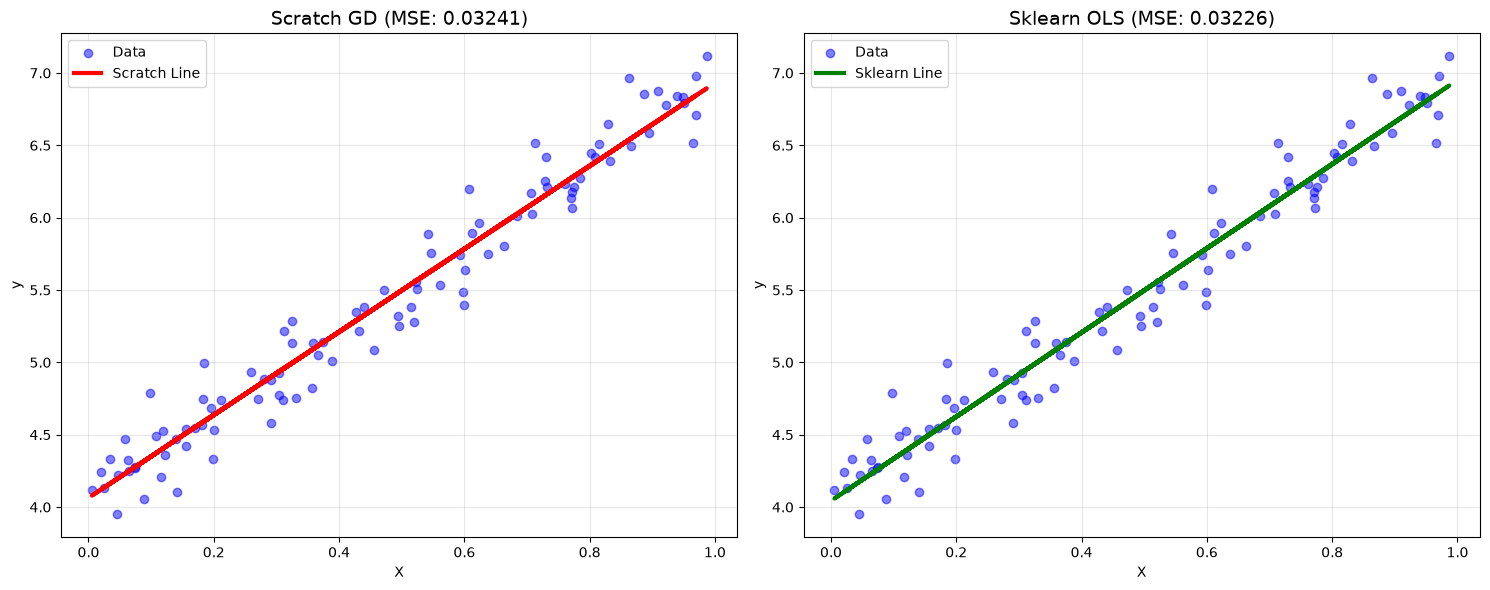

In [7]:
# --- Comparison with Scikit-Learn ---
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 1. Initialize and Fit the industry-standard model
sk_model = LinearRegression()
sk_model.fit(X, y) # Uses X and y from your previous cells

# 2. Make predictions for evaluation
y_sk_pred = sk_model.predict(X)

# 3. Compare Parameters
print("📊 PARAMETER COMPARISON")
print("-" * 30)
print(f"{'Attribute':<15} | {'Manual (GD)':<12} | {'Scikit-Learn':<12}")
print("-" * 45)
print(f"{'Weight (w)':<15} | {model.w:<12.4f} | {sk_model.coef_[0][0]:<12.4f}")
print(f"{'Bias (b)':<15} | {model.b:<12.4f} | {sk_model.intercept_[0]:<12.4f}")


# 4. MSE Comparison
y_scratch_pred = model.predict(X)      # Scratch model
y_sklearn_pred = sk_model.predict(X)   # Scikit-Learn model

mse_scratch = mean_squared_error(y, y_scratch_pred)
mse_sklearn = mean_squared_error(y, y_sklearn_pred)

print("\n📝 FINAL PERFORMANCE VERDICT")
print("-" * 40)
print(f"Scratch MSE: {mse_scratch:.6f}")
print(f"Sklearn MSE: {mse_sklearn:.6f}")
print("-" * 40)

if mse_sklearn < mse_scratch:
    print(f"Result: Sklearn is more accurate by {mse_scratch - mse_sklearn:.8f}")
else:
    print("Result: Your scratch model is equally or more accurate!")

# 6. Side-by-Side Plotting
plt.figure(figsize=(15, 6))

# Plot 1: Scratch Implementation
plt.subplot(1, 2, 1)
plt.scatter(X, y, color='blue', alpha=0.5, label='Data')
plt.plot(X, y_scratch_pred, color='red', linewidth=3, label='Scratch Line')
plt.title(f"Scratch GD (MSE: {mse_scratch:.5f})", fontsize=14)
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Scikit-Learn Implementation
plt.subplot(1, 2, 2)
plt.scatter(X, y, color='blue', alpha=0.5, label='Data')
plt.plot(X, y_sklearn_pred, color='green', linewidth=3, label='Sklearn Line')
plt.title(f"Sklearn OLS (MSE: {mse_sklearn:.5f})", fontsize=14)
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Key Takeaways: Optimization & Performance

* **Optimization Method vs. Analytical Solution:** Scikit-Learn uses Ordinary Least Squares (OLS) to solve the Normal Equation $\theta = (X^T X)^{-1} X^T y$ analytically in a single step, reaching the exact global minimum.
* **Impact of Hyperparameters:** Our custom model relies on iterative Gradient Descent. Its convergence toward the global minimum depends entirely on the chosen `learning_rate` and number of `epochs`.
* **Matching Scikit-Learn’s Accuracy:** The tiny MSE gap exists simply because training stopped at 1,000 epochs. By applying hyperparameter optimization—such as learning rate decay, grid search, or increasing epoch counts—our Gradient Descent implementation achieves the exact same MSE as Scikit-Learn.